# Análisis exploratorio y regresión lineal aplicados al riesgo de ciberseguridad

Este cuaderno presenta un estudio académico de eventos de red y seguridad en equipos informáticos. Se utiliza un conjunto de datos sintético y reproducible, diseñado exclusivamente con fines educativos y sin información real de personas, organizaciones o direcciones IP.

## Objetivos de aprendizaje

Al finalizar el ejercicio, el estudiante deberá ser capaz de:

1. Identificar la unidad de observación, las variables explicativas y la variable respuesta.
2. Interpretar mínimo, máximo, media, mediana, desviación estándar, cuartiles y rango intercuartílico.
3. Construir e interpretar histogramas, diagramas de dispersión y matrices de correlación.
4. Formular preguntas sobre relaciones entre variables sin confundir asociación con causalidad.
5. Derivar una regresión lineal simple mediante mínimos cuadrados ordinarios.
6. Comparar un modelo de referencia, una regresión simple y una regresión múltiple.
7. Interpretar MAE, RMSE, R², coeficientes y residuos.
8. Reconocer limitaciones metodológicas y éticas de un modelo de riesgo.

La variable respuesta será `risk_score`, un índice continuo entre 0 y 100. Por tratarse de una magnitud continua, la regresión lineal constituye un punto de partida razonable. Si el objetivo fuese clasificar un evento como ataque o no ataque, correspondería emplear un método de clasificación.

## 1. Diccionario de variables

La **unidad de observación** es una ventana de monitoreo de una hora para un equipo. Las direcciones IP son identificadores sintéticos y no se utilizarán como variables predictivas.

| Variable | Tipo y unidad | Definición | Interpretación inicial |
|---|---|---|---|
| `device_id` | Identificador | Código anónimo del equipo | Permite distinguir registros; no posee significado numérico. |
| `source_ip` | Identificador | Dirección IPv4 sintética y privada | No debe interpretarse como una magnitud ni incorporarse directamente al modelo. |
| `failed_logins` | Conteo por hora | Intentos de autenticación fallidos | Una frecuencia elevada puede indicar fuerza bruta o errores legítimos del usuario. |
| `connection_count` | Conteo por hora | Número total de conexiones observadas | Refleja intensidad de actividad, no necesariamente riesgo. |
| `unusual_port_connections` | Conteo por hora | Conexiones dirigidas a puertos poco habituales | Puede señalar escaneo, configuración especializada o tráfico anómalo. |
| `inbound_mb` | Megabytes por hora | Volumen recibido por el equipo | Valores elevados pueden corresponder a descargas normales o actividad anómala. |
| `outbound_mb` | Megabytes por hora | Volumen enviado por el equipo | Un aumento puede asociarse a copias de seguridad, servicios o exfiltración. |
| `off_hours_ratio` | Proporción [0, 1] | Fracción de actividad fuera del horario habitual | Una proporción alta requiere contexto operacional. |
| `encrypted_traffic_ratio` | Proporción [0, 1] | Fracción de tráfico cifrado | El cifrado protege datos, aunque también puede ocultar tráfico malicioso. |
| `patch_age_days` | Días | Antigüedad de la última actualización de seguridad | Valores altos indican mayor exposición potencial. |
| `known_vulnerabilities` | Conteo | Vulnerabilidades conocidas del equipo | Constituye una medida directa de superficie de ataque. |
| `endpoint_alerts` | Conteo por hora | Alertas emitidas por el sistema de protección | Una frecuencia elevada merece investigación. |
| `avg_packet_size` | Bytes | Tamaño promedio de los paquetes | Puede caracterizar patrones de tráfico, pero su relación con el riesgo no tiene por qué ser lineal. |
| `risk_score` | Índice [0, 100] | Variable respuesta sintética que resume el riesgo | Valores superiores representan mayor prioridad de investigación, no prueba de un incidente.

**Consideración ética:** ninguna métrica aislada demuestra actividad maliciosa. Un sistema real requeriría validación, trazabilidad, supervisión humana y controles contra decisiones automatizadas injustificadas.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
plt.style.use("seaborn-v0_8-whitegrid")

RANDOM_STATE = 42
TARGET = "risk_score"

def generate_security_data(n=1200, seed=RANDOM_STATE):
    """Generate reproducible, fictional network-monitoring observations."""
    rng = np.random.default_rng(seed)
    failed = rng.poisson(3.5, n)
    inbound = rng.lognormal(4.1, 0.7, n)
    outbound = 0.30 * inbound + rng.lognormal(3.3, 0.8, n)
    unusual_ports = rng.poisson(0.8 + 0.18 * failed, n)
    off_hours = rng.beta(2, 5, n)
    encrypted = rng.beta(8, 2, n)
    patch_age = np.clip(rng.gamma(2.2, 24, n), 0, 180)
    vulnerabilities = rng.poisson(0.3 + patch_age / 65, n)
    alerts = rng.poisson(0.4 + 0.18 * failed + 0.28 * vulnerabilities, n)
    connections = rng.gamma(5, 35, n)
    packet_size = np.clip(rng.normal(680, 150, n), 100, 1500)

    # The random term represents unobserved factors and measurement variation.
    noise = rng.normal(0, 6, n)
    risk = (
        15 + 2.3 * failed + 1.6 * unusual_ports + 0.025 * outbound
        + 24 * off_hours + 3.8 * vulnerabilities + 1.9 * alerts
        + 0.04 * patch_age - 9 * encrypted + noise
    )

    return pd.DataFrame({
        "device_id": [f"DEV-{i:04d}" for i in range(1, n + 1)],
        "source_ip": [f"10.{(i // 65000) % 256}.{(i // 250) % 256}.{(i % 250) + 1}" for i in range(n)],
        "failed_logins": failed,
        "connection_count": np.round(connections).astype(int),
        "unusual_port_connections": unusual_ports,
        "inbound_mb": inbound,
        "outbound_mb": outbound,
        "off_hours_ratio": off_hours,
        "encrypted_traffic_ratio": encrypted,
        "patch_age_days": patch_age,
        "known_vulnerabilities": vulnerabilities,
        "endpoint_alerts": alerts,
        "avg_packet_size": packet_size,
        TARGET: np.clip(risk, 0, 100),
    })

df = generate_security_data()
print(f"Observaciones: {len(df):,} | Variables: {df.shape[1]}")
df.head()

Observaciones: 1,200 | Variables: 14


,device_id,source_ip,failed_logins,connection_count,unusual_port_connections,inbound_mb,outbound_mb,off_hours_ratio,encrypted_traffic_ratio,patch_age_days,known_vulnerabilities,endpoint_alerts,avg_packet_size,risk_score
0,DEV-0001,10.0.0.1,4,137,2,51.741,63.817,0.125,0.846,60.421,0,2,413.552,33.017
1,DEV-0002,10.0.0.2,5,163,2,71.998,86.120,0.425,0.956,12.006,1,0,931.877,43.476
2,DEV-0003,10.0.0.3,5,285,3,43.171,25.556,0.087,0.842,61.642,2,0,621.288,27.949
3,DEV-0004,10.0.0.4,3,336,2,31.343,37.043,0.105,0.522,19.174,0,2,810.537,25.372
4,DEV-0005,10.0.0.5,5,244,1,26.266,16.857,0.413,0.825,15.279,0,0,708.303,31.173


## 2. Auditoría de calidad

Antes del análisis estadístico se verifican la estructura, los tipos, los valores ausentes, los duplicados y los recorridos imposibles. Esta acción es necesaria porque un modelo puede ejecutarse correctamente y, aun así, producir conclusiones inválidas si los datos son incoherentes.

- `shape` informa el número de observaciones y variables.
- `dtypes` permite separar magnitudes numéricas de identificadores.
- `isna().sum()` contabiliza información ausente.
- `duplicated().sum()` identifica registros repetidos.
- Las reglas de rango verifican que proporciones e índices permanezcan en sus intervalos teóricos.

In [2]:
audit = pd.DataFrame({
    "type": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "unique_values": df.nunique(),
})

print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Risk score within [0, 100]: {df[TARGET].between(0, 100).all()}")
print(f"Ratios within [0, 1]: {df[['off_hours_ratio', 'encrypted_traffic_ratio']].apply(lambda s: s.between(0, 1).all()).all()}")
audit

Duplicate rows: 0
Risk score within [0, 100]: True
Ratios within [0, 1]: True


,type,missing,unique_values
device_id,str,0,1200
source_ip,str,0,1200
failed_logins,int64,0,13
connection_count,int64,0,312
unusual_port_connections,int64,0,8
inbound_mb,float64,0,1200
outbound_mb,float64,0,1200
off_hours_ratio,float64,0,1200
encrypted_traffic_ratio,float64,0,1200
patch_age_days,float64,0,1196


## 3. Revisión de conceptos estadísticos descriptivos

- **Mínimo y máximo:** delimitan el recorrido observado y permiten detectar valores imposibles o extremos.
- **Media:** suma de las observaciones dividida por su número. Resume el centro, pero es sensible a valores extremos.
- **Mediana:** valor que divide la muestra ordenada en dos mitades. Resulta más robusta que la media.
- **Desviación estándar:** cuantifica la dispersión de las observaciones respecto de la media.
- **Q1 y Q3:** percentiles 25 y 75; delimitan la mitad central de los datos.
- **IQR:** diferencia $Q_3-Q_1$. Una regla exploratoria considera atípicos los valores inferiores a $Q_1-1.5\,IQR$ o superiores a $Q_3+1.5\,IQR$.
- **Asimetría:** describe la falta de simetría de la distribución. Una diferencia apreciable entre media y mediana suele anticiparla.

Estos estadísticos son útiles para comprender escalas y distribuciones, pero no explican por sí solos las relaciones entre variables ni establecen causalidad.

In [3]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()

profile = df[numeric_columns].describe().T.rename(columns={
    "count": "n", "mean": "mean", "std": "std_dev",
    "min": "min", "25%": "Q1", "50%": "median", "75%": "Q3", "max": "max",
})
profile["IQR"] = profile["Q3"] - profile["Q1"]
profile["skewness"] = df[numeric_columns].skew()
profile

,n,mean,std_dev,min,Q1,median,Q3,max,IQR,skewness
failed_logins,"1,200.000",3.437,1.881,0.000,2.000,3.000,5.000,12.000,3.000,0.592
connection_count,"1,200.000",174.591,79.669,33.000,115.000,162.000,220.250,479.000,105.250,0.861
unusual_port_connections,"1,200.000",1.454,1.261,0.000,0.000,1.000,2.000,8.000,2.000,0.882
inbound_mb,"1,200.000",81.171,65.525,2.794,38.872,62.400,102.558,583.405,63.686,2.642
outbound_mb,"1,200.000",61.215,39.442,4.342,35.430,50.936,77.189,399.566,41.758,2.466
off_hours_ratio,"1,200.000",0.280,0.159,0.009,0.155,0.262,0.379,0.878,0.224,0.620
encrypted_traffic_ratio,"1,200.000",0.801,0.123,0.246,0.729,0.826,0.895,0.994,0.166,-0.870
patch_age_days,"1,200.000",53.067,34.519,0.491,26.939,47.345,70.052,180.000,43.113,1.051
known_vulnerabilities,"1,200.000",1.081,1.148,0.000,0.000,1.000,2.000,7.000,2.000,1.317
endpoint_alerts,"1,200.000",1.353,1.268,0.000,0.000,1.000,2.000,9.000,2.000,1.116


### Preguntas de investigación: estadística descriptiva

Registre sus respuestas en una celda markdown adicional e incluya evidencia numérica.

1. ¿Qué variable presenta el mayor recorrido absoluto? ¿Es válido concluir que es la más importante para predecir el riesgo?
2. ¿En qué variables difieren de forma apreciable la media y la mediana? ¿Qué indica esta diferencia?
3. ¿Qué variables presentan mayor asimetría positiva?
4. Calcule manualmente el IQR de `outbound_mb` con los valores de la tabla.
5. Proponga una explicación legítima y una explicación potencialmente riesgosa para un valor elevado de `outbound_mb`.
6. ¿Por qué `device_id` y `source_ip` no aparecen en el perfil numérico?

## 4. Visualización de distribuciones

Un histograma divide el recorrido de una variable en intervalos y representa la frecuencia de observaciones en cada intervalo. Permite identificar concentración, dispersión, asimetría, valores extremos y posibles subgrupos.

La línea roja representa la media y la línea negra discontinua la mediana. Su separación proporciona una indicación visual de asimetría. El número de intervalos modifica el nivel de detalle, por lo que no debe interpretarse como una propiedad fija de los datos.

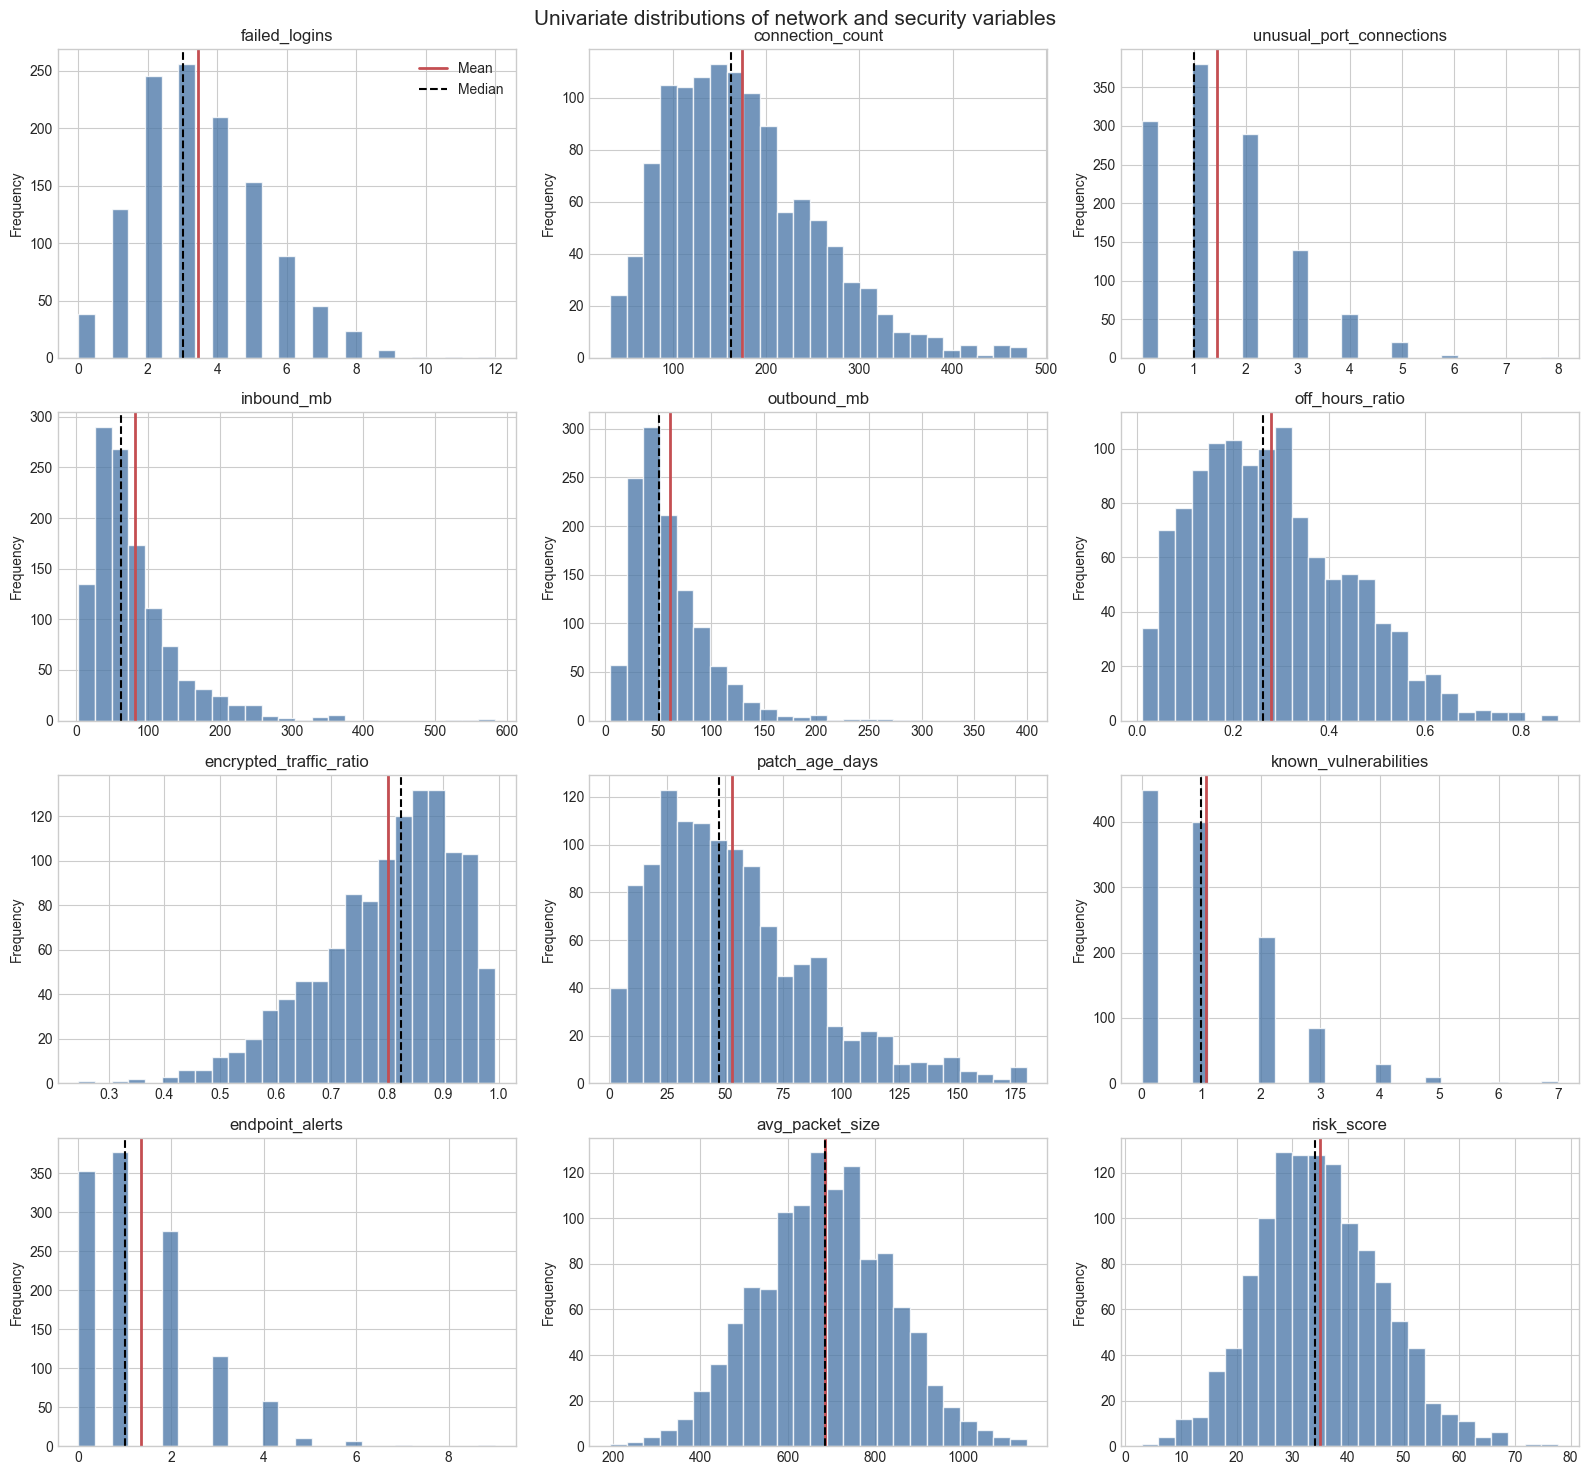

In [4]:
plot_columns = [
    "failed_logins", "connection_count", "unusual_port_connections",
    "inbound_mb", "outbound_mb", "off_hours_ratio",
    "encrypted_traffic_ratio", "patch_age_days",
    "known_vulnerabilities", "endpoint_alerts",
    "avg_packet_size", TARGET,
]

fig, axes = plt.subplots(4, 3, figsize=(16, 15))
for ax, column in zip(axes.flat, plot_columns):
    ax.hist(df[column], bins=25, color="#4C78A8", alpha=0.78, edgecolor="white")
    ax.axvline(df[column].mean(), color="#C44E52", linewidth=2, label="Mean")
    ax.axvline(df[column].median(), color="black", linestyle="--", linewidth=1.5, label="Median")
    ax.set_title(column)
    ax.set_ylabel("Frequency")
axes[0, 0].legend()
fig.suptitle("Univariate distributions of network and security variables", fontsize=15)
plt.tight_layout()
plt.show()

### Preguntas de investigación: histogramas

1. Identifique dos distribuciones aproximadamente simétricas y dos distribuciones asimétricas.
2. ¿En qué gráficos la media es superior a la mediana? Relacione la respuesta con el signo de la asimetría en la tabla anterior.
3. ¿Por qué una concentración en cero puede ser válida en variables de conteo?
4. ¿Qué distribuciones sugieren la presencia de observaciones extremas?
5. ¿Qué limitación presenta un histograma para estudiar la relación entre una variable y `risk_score`?

## 5. Filtros y comparación de grupos

La segmentación permite contrastar subpoblaciones que un promedio global puede ocultar. En primer lugar, `patch_age_days` se divide en cuartiles de tamaño comparable. Posteriormente se construye un filtro conjunto para estudiar ventanas con actividad fuera de horario y volumen saliente elevados.

Estas comparaciones son descriptivas. Una diferencia entre grupos no demuestra que una variable sea la causa del riesgo, dado que otras características pueden variar simultáneamente.

In [5]:
df["patch_age_group"] = pd.qcut(
    df["patch_age_days"], q=4,
    labels=["Q1: most recent", "Q2", "Q3", "Q4: oldest"],
)

patch_summary = df.groupby("patch_age_group", observed=True).agg(
    observations=(TARGET, "size"),
    average_risk=(TARGET, "mean"),
    median_risk=(TARGET, "median"),
    average_vulnerabilities=("known_vulnerabilities", "mean"),
)

off_hours_limit = df["off_hours_ratio"].quantile(0.75)
outbound_limit = df["outbound_mb"].quantile(0.75)
high_activity = df.query(
    "off_hours_ratio >= @off_hours_limit and outbound_mb >= @outbound_limit"
)

print("Risk by patch-age quartile")
display(patch_summary)
print(f"\nCombined filter: {len(high_activity)} observations")
display(high_activity[["device_id", "source_ip", "off_hours_ratio", "outbound_mb", TARGET]].head(10))
print(f"Filtered average risk: {high_activity[TARGET].mean():.2f}")
print(f"Overall average risk:  {df[TARGET].mean():.2f}")

Risk by patch-age quartile


,observations,average_risk,median_risk,average_vulnerabilities
patch_age_group,,,,
Q1: most recent,300,31.473,30.769,0.553
Q2,300,33.039,32.480,0.810
Q3,300,35.314,34.923,1.143
Q4: oldest,300,40.054,39.320,1.817



Combined filter: 77 observations


,device_id,source_ip,off_hours_ratio,outbound_mb,risk_score
1,DEV-0002,10.0.0.2,0.425,86.120,43.476
19,DEV-0020,10.0.0.20,0.383,156.664,27.849
34,DEV-0035,10.0.0.35,0.565,168.578,52.986
40,DEV-0041,10.0.0.41,0.396,100.297,54.841
47,DEV-0048,10.0.0.48,0.616,274.261,35.438
61,DEV-0062,10.0.0.62,0.420,102.134,27.528
62,DEV-0063,10.0.0.63,0.422,92.974,35.200
80,DEV-0081,10.0.0.81,0.501,94.392,33.253
104,DEV-0105,10.0.0.105,0.460,91.410,41.859
121,DEV-0122,10.0.0.122,0.414,93.014,37.057


Filtered average risk: 41.69
Overall average risk:  34.97


### Preguntas de investigación: filtros

1. ¿Cómo varía el riesgo promedio entre los cuartiles de antigüedad de actualización?
2. ¿La mediana confirma el mismo patrón que la media?
3. Compare el riesgo medio del filtro conjunto con el promedio global.
4. ¿Por qué el resultado del filtro no permite concluir que la actividad fuera de horario causa un incidente?
5. Modifique uno de los umbrales del filtro. ¿La conclusión permanece estable?

## 6. Correlación y diagramas de dispersión

El coeficiente de Pearson cuantifica la dirección y la intensidad de una asociación lineal:

$$r_{XY}=\frac{\operatorname{cov}(X,Y)}{s_Xs_Y}, \qquad -1\leq r_{XY}\leq1$$

Los valores próximos a +1 indican asociación lineal positiva; los próximos a −1, asociación negativa; y los próximos a cero, ausencia de una asociación lineal clara. Un valor próximo a cero no descarta relaciones curvilíneas.

La matriz de correlación permite estudiar simultáneamente las relaciones con `risk_score` y entre los propios regresores. Los diagramas de dispersión permiten comprobar si la forma de la relación es compatible con una recta y si existen observaciones extremas.

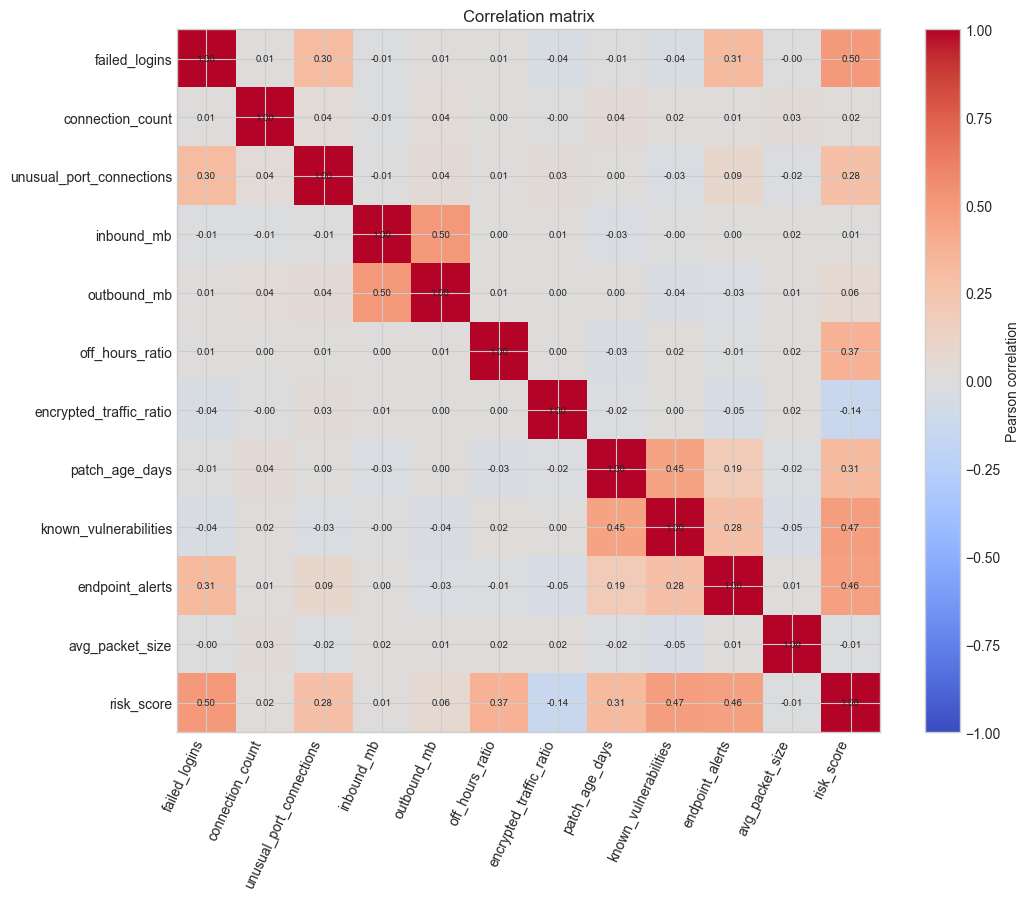

Correlations with risk_score


,correlation
failed_logins,0.497
known_vulnerabilities,0.474
endpoint_alerts,0.462
off_hours_ratio,0.367
patch_age_days,0.315
unusual_port_connections,0.280
encrypted_traffic_ratio,-0.135
outbound_mb,0.060
connection_count,0.023
avg_packet_size,-0.011


Strongest absolute linear association: failed_logins


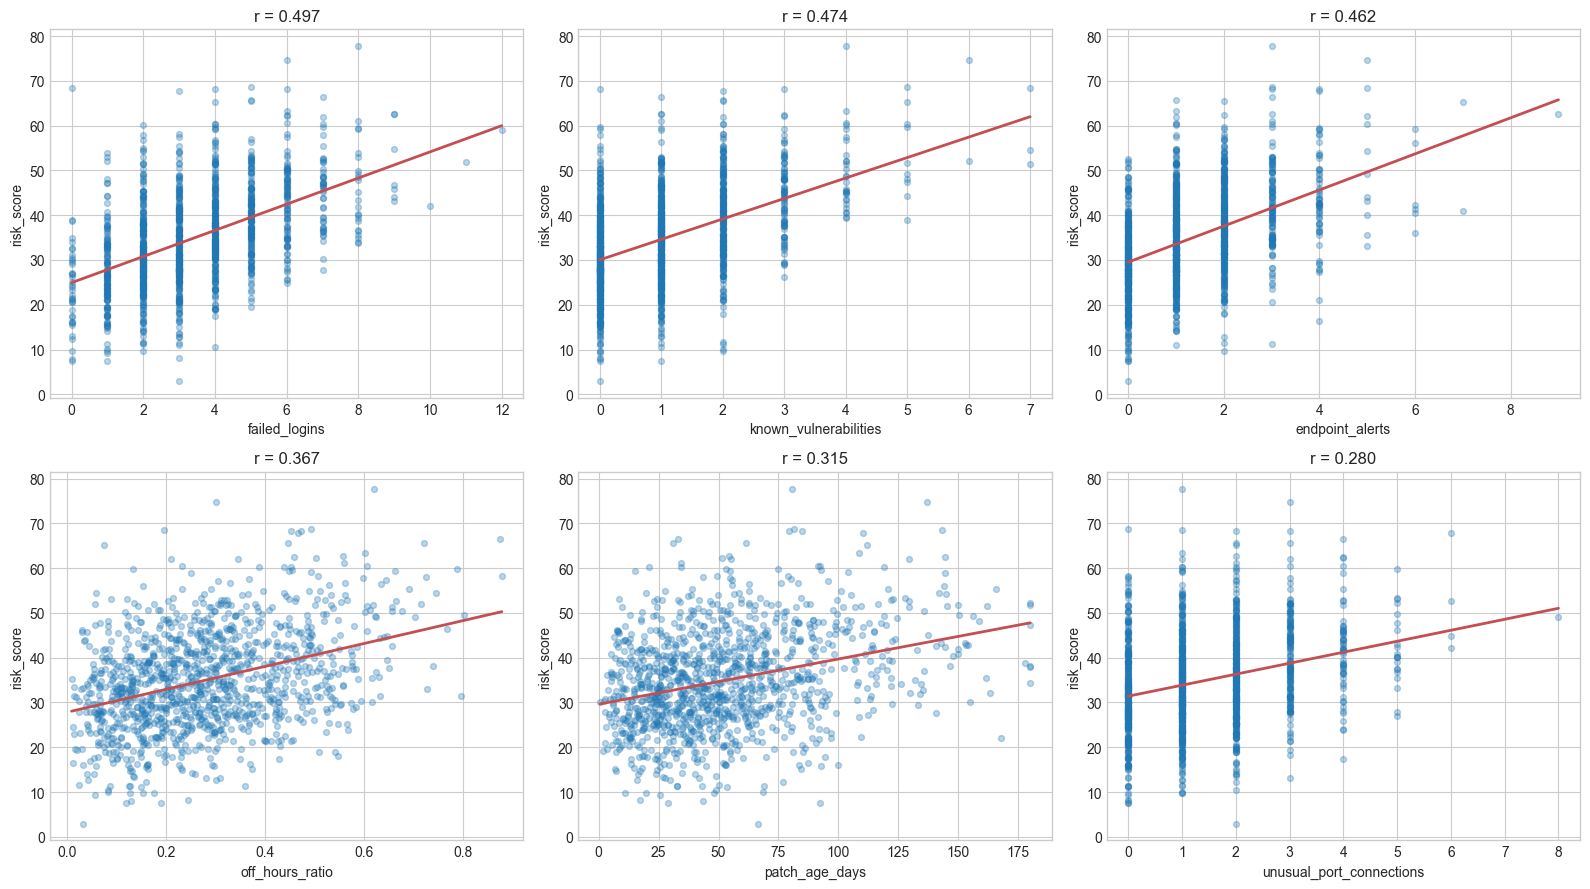

In [6]:
features = [column for column in numeric_columns if column != TARGET]
corr = df[features + [TARGET]].corr()
target_corr = corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
most_significant = target_corr.index[0]

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=65, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

print("Correlations with risk_score")
display(target_corr.to_frame("correlation"))
print(f"Strongest absolute linear association: {most_significant}")

selected = target_corr.index[:6]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, column in zip(axes.flat, selected):
    ax.scatter(df[column], df[TARGET], alpha=0.30, s=18)
    slope, intercept = np.polyfit(df[column], df[TARGET], 1)
    x_line = np.linspace(df[column].min(), df[column].max(), 100)
    ax.plot(x_line, intercept + slope * x_line, color="#C44E52", linewidth=2)
    ax.set_xlabel(column)
    ax.set_ylabel(TARGET)
    ax.set_title(f"r = {corr.loc[column, TARGET]:.3f}")
plt.tight_layout()
plt.show()

### Preguntas de investigación: relaciones entre variables

1. Ordene las tres variables con mayor correlación absoluta con `risk_score`.
2. Interprete el signo de cada una de esas correlaciones en el contexto de seguridad.
3. Identifique una variable con correlación próxima a cero. ¿Puede concluirse que carece de utilidad operativa?
4. ¿Qué pares de variables explicativas presentan asociación entre sí? ¿Cómo podría afectar esto a una regresión múltiple?
5. ¿Qué diagramas muestran una relación compatible con una recta? ¿Cuáles presentan mayor dispersión?
6. Explique por qué una correlación alta no demuestra que una variable cause el riesgo.

## 7. Regresión lineal simple y mínimos cuadrados ordinarios

La regresión lineal simple aproxima la variable respuesta mediante:

$$\hat y=b_0+b_1x$$

Los estimadores de mínimos cuadrados ordinarios minimizan la suma de cuadrados de los residuos, $\sum_i(y_i-\hat y_i)^2$, y se calculan mediante:

$$b_1=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sum_i(x_i-\bar{x})^2}, \qquad b_0=\bar{y}-b_1\bar{x}$$

La pendiente $b_1$ representa el cambio esperado en `risk_score` por cada unidad adicional de $x$. El intercepto $b_0$ corresponde al valor ajustado cuando $x=0$, aunque su interpretación puede carecer de sentido si cero se encuentra fuera del recorrido observado. El residuo $e_i=y_i-\hat y_i$ mide el error de ajuste de cada observación.

La siguiente demostración utiliza ocho observaciones distribuidas a lo largo del recorrido de la variable más correlacionada. Su finalidad es geométrica y no constituye una evaluación del desempeño.

Manual equation: risk_score = 23.721 + (2.858 × failed_logins)
Sum of squared residuals: 120.676


,failed_logins,risk_score,predicted_risk,residual,squared_residual
0,0,22.173,23.721,-1.548,2.395
171,2,28.456,29.436,-0.980,0.961
342,2,31.086,29.436,1.650,2.721
513,3,37.664,32.294,5.370,28.839
685,4,32.223,35.152,-2.929,8.580
856,4,39.922,35.152,4.770,22.757
1027,5,30.698,38.010,-7.312,53.465
1199,12,58.993,58.015,0.979,0.958


Matches scikit-learn: True


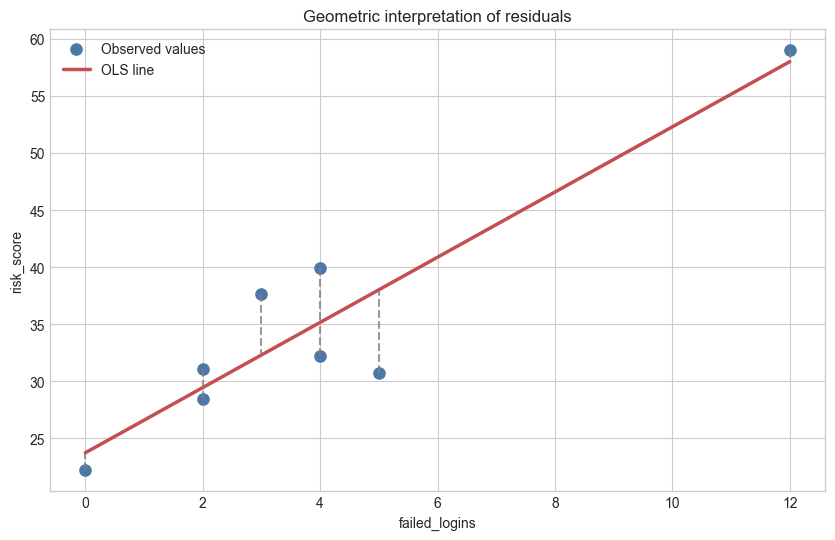

In [7]:
ordered = df.sort_values(most_significant).reset_index(drop=True)
positions = np.linspace(0, len(ordered) - 1, 8, dtype=int)
mini = ordered.loc[positions, [most_significant, TARGET]].copy()

x = mini[most_significant].to_numpy()
y = mini[TARGET].to_numpy()
b1 = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean()) ** 2)
b0 = y.mean() - b1 * x.mean()
mini["predicted_risk"] = b0 + b1 * x
mini["residual"] = y - mini["predicted_risk"]
mini["squared_residual"] = mini["residual"] ** 2

print(f"Manual equation: risk_score = {b0:.3f} + ({b1:.3f} × {most_significant})")
print(f"Sum of squared residuals: {mini['squared_residual'].sum():.3f}")
display(mini)

model_check = LinearRegression().fit(mini[[most_significant]], mini[TARGET])
print("Matches scikit-learn:", np.allclose([b0, b1], [model_check.intercept_, model_check.coef_[0]]))

x_line = np.linspace(x.min(), x.max(), 100)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, s=65, color="#4C78A8", label="Observed values")
plt.plot(x_line, b0 + b1 * x_line, color="#C44E52", linewidth=2.5, label="OLS line")
for xi, yi, yhat in zip(x, y, mini["predicted_risk"]):
    plt.plot([xi, xi], [yi, yhat], color="gray", linestyle="--", alpha=0.8)
plt.xlabel(most_significant)
plt.ylabel(TARGET)
plt.title("Geometric interpretation of residuals")
plt.legend()
plt.show()

### Preguntas de investigación: cálculo de la recta

1. Interprete el signo y la magnitud de la pendiente obtenida.
2. ¿Qué representa cada segmento vertical del gráfico?
3. ¿Por qué los residuos se elevan al cuadrado durante la estimación?
4. ¿Qué observación ejerce mayor influencia sobre la suma de errores cuadrados?
5. ¿Por qué no debe utilizarse esta submuestra de ocho observaciones para evaluar el modelo?
6. Verifique manualmente la predicción y el residuo de una de las filas.

## 8. Evaluación predictiva: referencia, modelo simple y modelo múltiple

Los datos se separan en entrenamiento y prueba. La partición de entrenamiento se utiliza para estimar los coeficientes; la de prueba permanece sin observar durante el ajuste y proporciona una evaluación más objetiva.

Se comparan tres especificaciones sobre las mismas observaciones de prueba:

1. **Referencia:** siempre predice la media de `risk_score` del entrenamiento.
2. **Regresión simple:** emplea la variable de mayor correlación absoluta.
3. **Regresión múltiple:** emplea todas las magnitudes numéricas disponibles.

Métricas:

$$\mathrm{MAE}=\frac{1}{n}\sum_i|y_i-\hat y_i|$$

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_i(y_i-\hat y_i)^2}$$

$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}$$

Los valores inferiores de MAE y RMSE representan menor error. Un R² próximo a 1 indica elevada capacidad explicativa; cero equivale aproximadamente a predecir la media; un valor negativo indica un desempeño inferior al modelo de referencia.

,MAE,RMSE,R2
model,,,
Mean baseline,8.956,11.172,-0.000
Simple: failed_logins,7.802,9.751,0.238
Multiple: all features,4.398,5.568,0.752


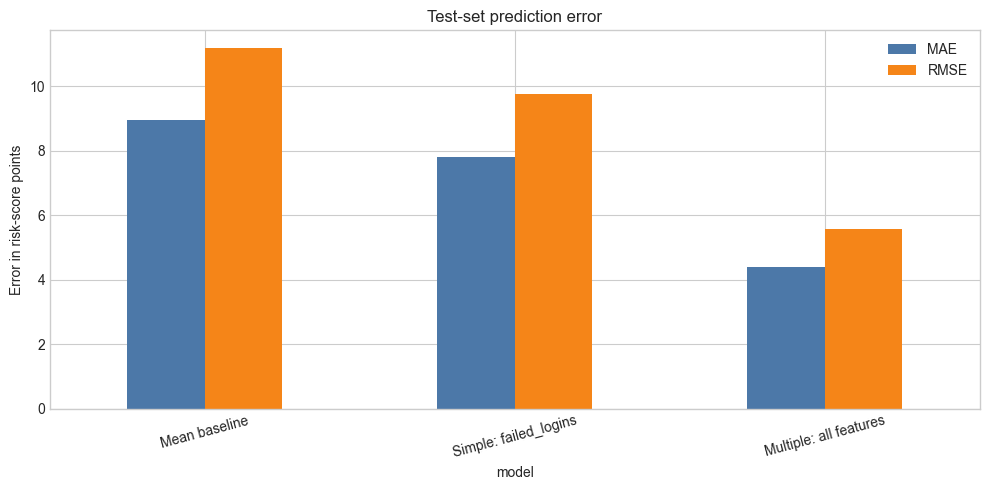

Simple equation: risk_score = 24.936 + (2.926 × failed_logins)
R² improvement from simple to multiple: +0.514


In [8]:
train_index, test_index = train_test_split(
    df.index, test_size=0.25, random_state=RANDOM_STATE
)
X_train = df.loc[train_index, features]
X_test = df.loc[test_index, features]
y_train = df.loc[train_index, TARGET]
y_test = df.loc[test_index, TARGET]

simple_model = LinearRegression().fit(X_train[[most_significant]], y_train)
multiple_model = LinearRegression().fit(X_train, y_train)

predictions = {
    "Mean baseline": np.full(len(y_test), y_train.mean()),
    f"Simple: {most_significant}": simple_model.predict(X_test[[most_significant]]),
    "Multiple: all features": multiple_model.predict(X_test),
}

rows = []
for name, y_pred in predictions.items():
    rows.append({
        "model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred),
    })
metrics = pd.DataFrame(rows).set_index("model")
display(metrics)

ax = metrics[["MAE", "RMSE"]].plot.bar(figsize=(10, 5), color=["#4C78A8", "#F58518"])
ax.set_ylabel("Error in risk-score points")
ax.set_title("Test-set prediction error")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

print(f"Simple equation: risk_score = {simple_model.intercept_:.3f} + ({simple_model.coef_[0]:.3f} × {most_significant})")
print(f"R² improvement from simple to multiple: {metrics.loc['Multiple: all features', 'R2'] - metrics.loc[f'Simple: {most_significant}', 'R2']:+.3f}")

### Preguntas de investigación: métricas

1. ¿Qué modelo presenta el menor MAE? Interprete el valor en puntos de `risk_score`.
2. ¿Qué modelo presenta el menor RMSE?
3. ¿Por qué el RMSE es superior al MAE en las tres especificaciones?
4. ¿Qué proporción de variabilidad explica el modelo simple? ¿Y el múltiple?
5. Calcule la mejora absoluta de R² al incorporar el resto de variables.
6. ¿La incorporación de todas las columnas garantiza siempre una mejora sobre datos nuevos? Justifique.
7. Interprete la ecuación de la regresión simple en el contexto del problema.
8. Si un modelo obtiene R² elevado, ¿puede concluirse que identificó las causas de los incidentes?

## 9. Interpretación de coeficientes estandarizados

Los coeficientes expresados en unidades originales no pueden compararse directamente porque las variables utilizan escalas distintas. Para resolverlo se estandariza cada regresor:

$$z_j=\frac{x_j-\bar{x}_j}{s_j}$$

En el modelo estandarizado, cada coeficiente representa el cambio esperado en `risk_score` ante un incremento de una desviación estándar del regresor, manteniendo constantes los restantes. La magnitud absoluta permite comparar contribuciones dentro del modelo; el signo indica la dirección de la asociación parcial.

La importancia predictiva no equivale a causalidad ni a importancia operativa. Además, la correlación entre regresores puede alterar la magnitud y estabilidad de los coeficientes.

,standardized_coefficient
encrypted_traffic_ratio,-1.151
inbound_mb,-0.176
connection_count,0.113
avg_packet_size,0.168
outbound_mb,0.597
patch_age_days,1.162
unusual_port_connections,1.638
endpoint_alerts,2.161
off_hours_ratio,3.935
known_vulnerabilities,4.041


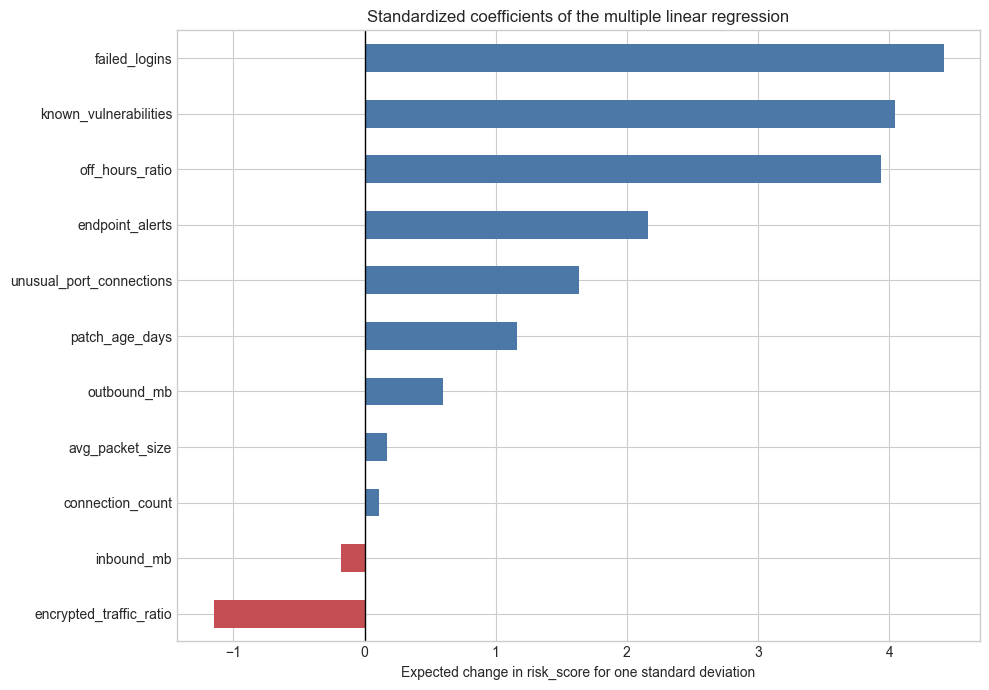

In [9]:
standardized_model = make_pipeline(StandardScaler(), LinearRegression())
standardized_model.fit(X_train, y_train)
standardized_coefficients = pd.Series(
    standardized_model.named_steps["linearregression"].coef_,
    index=features,
    name="standardized_coefficient",
).sort_values()

display(standardized_coefficients.to_frame())
colors = ["#C44E52" if value < 0 else "#4C78A8" for value in standardized_coefficients]
ax = standardized_coefficients.plot.barh(figsize=(10, 7), color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlabel("Expected change in risk_score for one standard deviation")
ax.set_title("Standardized coefficients of the multiple linear regression")
plt.tight_layout()
plt.show()

### Preguntas de investigación: coeficientes

1. ¿Qué tres variables presentan los coeficientes estandarizados de mayor magnitud absoluta?
2. Interprete el coeficiente de `encrypted_traffic_ratio`. ¿Implica su signo que todo tráfico cifrado es seguro?
3. Identifique variables cuyo coeficiente sea próximo a cero. ¿Coincide esto con su correlación individual?
4. Explique la expresión “manteniendo constantes las demás variables”.
5. ¿Por qué no es válido comparar directamente los coeficientes calculados en unidades originales?
6. ¿Qué riesgo analítico existe si dos regresores contienen información muy similar?

## 10. Diagnóstico mediante residuos

Un modelo puede obtener métricas agregadas aceptables y presentar errores sistemáticos en segmentos concretos. Se inspeccionan dos gráficos:

- **Valores observados frente a valores predichos:** un ajuste adecuado concentra los puntos alrededor de la diagonal $\hat y=y$.
- **Residuos frente a predicción:** un ajuste lineal adecuado produce una nube sin estructura alrededor de cero.

Una curva sugiere no linealidad; un embudo sugiere varianza no constante; y puntos aislados pueden indicar observaciones atípicas o factores omitidos. Un residuo elevado no demuestra que el registro sea incorrecto.

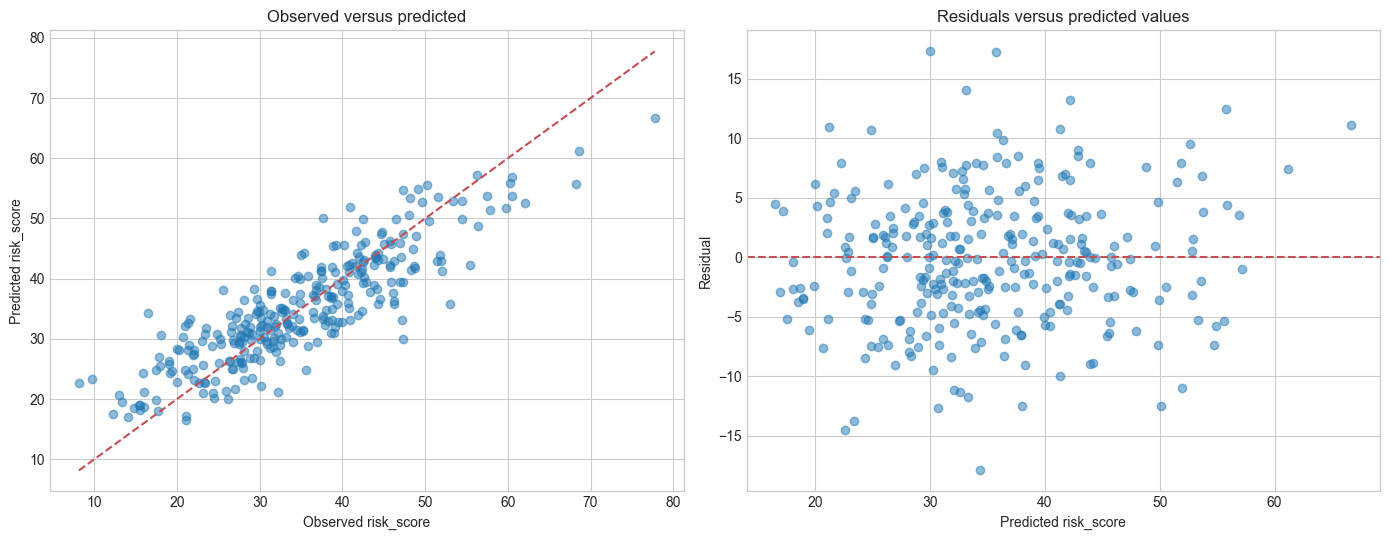

Five observations with the largest absolute errors


,device_id,source_ip,risk_score,predicted_risk,residual,absolute_error,failed_logins,known_vulnerabilities,endpoint_alerts
123,DEV-0124,10.0.0.124,16.461,34.357,-17.896,17.896,3,1,4
354,DEV-0355,10.0.1.105,47.292,30.000,17.292,17.292,1,2,0
889,DEV-0890,10.0.3.140,52.986,35.761,17.225,17.225,1,2,2
490,DEV-0491,10.0.1.241,8.130,22.611,-14.481,14.481,3,0,0
643,DEV-0644,10.0.2.144,47.168,33.119,14.049,14.049,5,0,1


In [10]:
y_pred_multiple = predictions["Multiple: all features"]
diagnostics = df.loc[test_index, ["device_id", "source_ip"] + features + [TARGET]].copy()
diagnostics["predicted_risk"] = y_pred_multiple
diagnostics["residual"] = diagnostics[TARGET] - diagnostics["predicted_risk"]
diagnostics["absolute_error"] = diagnostics["residual"].abs()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(diagnostics[TARGET], diagnostics["predicted_risk"], alpha=0.5)
limits = [min(diagnostics[TARGET].min(), diagnostics["predicted_risk"].min()),
          max(diagnostics[TARGET].max(), diagnostics["predicted_risk"].max())]
axes[0].plot(limits, limits, "--", color="#C44E52")
axes[0].set_xlabel("Observed risk_score")
axes[0].set_ylabel("Predicted risk_score")
axes[0].set_title("Observed versus predicted")

axes[1].scatter(diagnostics["predicted_risk"], diagnostics["residual"], alpha=0.5)
axes[1].axhline(0, linestyle="--", color="#C44E52")
axes[1].set_xlabel("Predicted risk_score")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals versus predicted values")
plt.tight_layout()
plt.show()

print("Five observations with the largest absolute errors")
display(diagnostics.nlargest(5, "absolute_error")[[
    "device_id", "source_ip", TARGET, "predicted_risk", "residual", "absolute_error",
    "failed_logins", "known_vulnerabilities", "endpoint_alerts"
]])

### Preguntas de investigación: diagnóstico

1. ¿Los puntos del primer gráfico se concentran alrededor de la diagonal?
2. ¿Los residuos presentan curvatura, forma de embudo o desplazamiento sistemático?
3. ¿Qué observación presenta el mayor error absoluto?
4. Investigue sus regresores: ¿se encuentra en una región extrema del conjunto de datos?
5. ¿Qué factores de seguridad ausentes podrían explicar errores elevados?
6. ¿Sería apropiado eliminar automáticamente estas observaciones? Justifique.
7. ¿Qué consecuencias tendría utilizar el modelo fuera de los recorridos observados durante el entrenamiento?

## 11. Aplicación del modelo a una observación nueva

La siguiente celda permite modificar los valores de una ventana de monitoreo y obtener una estimación del riesgo. La predicción debe interpretarse como una prioridad cuantitativa generada por un modelo educativo, no como confirmación de un ataque.

Antes de ejecutar, formule una hipótesis: ¿qué ocurrirá si aumentan simultáneamente los intentos fallidos, las vulnerabilidades conocidas y las alertas? Después modifique una variable cada vez para distinguir su efecto parcial.

La regresión lineal no restringe sus predicciones al intervalo [0, 100]. Por tanto, una combinación extrema puede producir un valor inferior a 0 o superior a 100. Este comportamiento constituye una limitación de la especificación, y no debe ocultarse mediante truncamiento automático durante la evaluación.

In [11]:
new_observation = pd.DataFrame([{
    "failed_logins": 9,
    "connection_count": 220,
    "unusual_port_connections": 4,
    "inbound_mb": 95.0,
    "outbound_mb": 140.0,
    "off_hours_ratio": 0.65,
    "encrypted_traffic_ratio": 0.72,
    "patch_age_days": 90.0,
    "known_vulnerabilities": 4,
    "endpoint_alerts": 5,
    "avg_packet_size": 720.0,
}])[features]

predicted_risk = multiple_model.predict(new_observation)[0]
new_observation.assign(predicted_risk_score=predicted_risk)

,failed_logins,connection_count,unusual_port_connections,inbound_mb,outbound_mb,off_hours_ratio,encrypted_traffic_ratio,patch_age_days,known_vulnerabilities,endpoint_alerts,avg_packet_size,predicted_risk_score
0,9,220,4,95.000,140.000,0.650,0.720,90.000,4,5,720.000,80.880


## 12. Informe final del estudiante

Elabore un informe breve que incluya:

1. Una descripción de la unidad de observación, la variable respuesta y los regresores.
2. Cinco conclusiones sustentadas con estadísticos descriptivos.
3. La interpretación de tres histogramas y tres diagramas de dispersión.
4. La interpretación de las correlaciones más relevantes, sin formular afirmaciones causales.
5. La ecuación de regresión simple y la interpretación de su pendiente.
6. Una comparación cuantitativa entre referencia, modelo simple y modelo múltiple mediante MAE, RMSE y R².
7. La interpretación de los tres coeficientes estandarizados de mayor magnitud.
8. Un diagnóstico de los residuos y de las observaciones con mayor error.
9. Dos limitaciones del conjunto de datos sintético y dos variables adicionales que recopilaría en un estudio real.
10. Una recomendación sobre el uso responsable del modelo.

### Criterio metodológico final

La regresión lineal resulta útil cuando el objetivo es continuo, la relación puede aproximarse mediante una combinación lineal, los residuos carecen de patrones sistemáticos y la interpretabilidad es prioritaria. No resulta suficiente cuando predominan interacciones complejas, relaciones no lineales, cambios temporales, datos de baja calidad o decisiones que requieren evidencia causal. En ciberseguridad, una predicción debe complementar —no sustituir— la investigación realizada por personal especializado.